# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [ ]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [ ]:
# Inspect the shapes of the datasets
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print("y_train_cat shape:", y_train_cat.shape)
print("y_test_cat shape:", y_test_cat.shape)


X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)
y_train_cat shape: (60000, 10)
y_test_cat shape: (10000, 10)


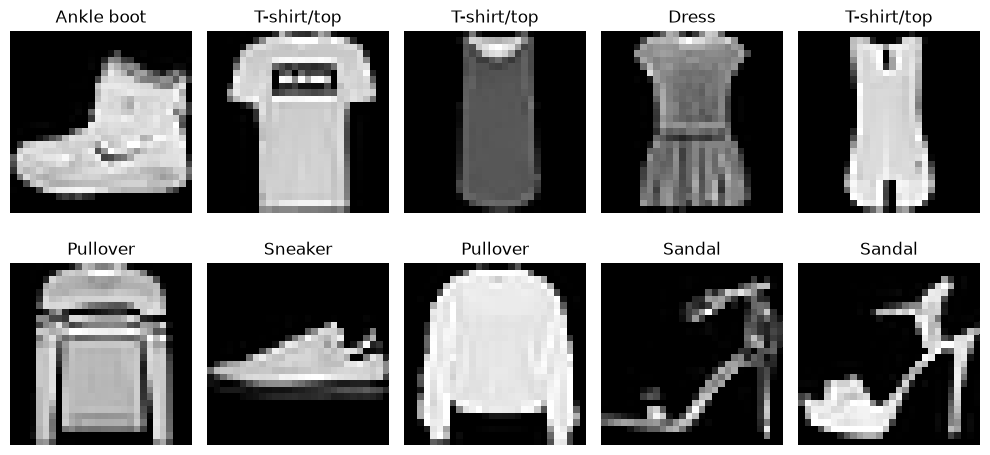

In [ ]:
import matplotlib.pyplot as plt
# Verify the data looks as expected
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()


Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

**Your answer here**

***Does the data look as expected?***

Yes. The images are 28×28 grayscale pictures of clothing, and the labels match the pictures. Ankle boot, T-shirts, dress, pullovers, sneaker and sandals are all labeled correctly.

***How is the image quality?*** 

It's low resolution and blurry because the images are tiny (they're pixelated because they're only 28×28). The items are centered and clean, with simple backgrounds. I can still tell what most items are. There are a few ambiguous items: the second and fourth "T-shirt/top" images look like tank tops or sleeveless garments but I may be mistaken - I am not a garment expert.

***Any issues?***

Some classes look alike, such as shirt, T-shirt and pullover, or sneaker and ankle boot. These will probably be confused most often.
The images are low resolution and grayscale, so there's no color or fine detail. 

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Flatten
import tensorflow as tf

# Create a simple linear regression model
model = Sequential()
# You can use `model.add(<layer>)` to add layers to the model
model.add(Flatten(input_shape=(28, 28)))
model.add(Dense(10))  # no activation = linear output, one unit per class

# Compile the model using `model.compile()`
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

# Train the model with `model.fit()`
history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=2,
)

# Evaluate the model with `model.evaluate()`
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.4f}")

Epoch 1/10


d:\sourcecodeforUofTDSI\MachineLearningFoundations2\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


422/422 - 1s - 2ms/step - accuracy: 0.7524 - loss: 0.7542 - val_accuracy: 0.8108 - val_loss: 0.5513
Epoch 2/10
422/422 - 0s - 837us/step - accuracy: 0.8259 - loss: 0.5238 - val_accuracy: 0.8295 - val_loss: 0.4932
Epoch 3/10
422/422 - 0s - 825us/step - accuracy: 0.8393 - loss: 0.4809 - val_accuracy: 0.8373 - val_loss: 0.4643
Epoch 4/10
422/422 - 0s - 820us/step - accuracy: 0.8454 - loss: 0.4577 - val_accuracy: 0.8405 - val_loss: 0.4534
Epoch 5/10
422/422 - 0s - 847us/step - accuracy: 0.8485 - loss: 0.4436 - val_accuracy: 0.8455 - val_loss: 0.4421
Epoch 6/10
422/422 - 0s - 1ms/step - accuracy: 0.8527 - loss: 0.4321 - val_accuracy: 0.8495 - val_loss: 0.4338
Epoch 7/10
422/422 - 0s - 822us/step - accuracy: 0.8552 - loss: 0.4239 - val_accuracy: 0.8523 - val_loss: 0.4279
Epoch 8/10
422/422 - 0s - 818us/step - accuracy: 0.8566 - loss: 0.4175 - val_accuracy: 0.8513 - val_loss: 0.4238
Epoch 9/10
422/422 - 0s - 823us/step - accuracy: 0.8584 - loss: 0.4129 - val_accuracy: 0.8535 - val_loss: 0.422

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

**Performance:** The baseline reached about 83.6% test accuracy (test loss 0.4667). Training accuracy was about 86% and validation accuracy about 85%.

**Versus expectations:** This is better than I expected for a model with no hidden layers and no convolutions. It is far above random guessing (10%), but about 1 in 6 images is still misclassified.

**Why:** A single linear layer can only draw straight-line boundaries on raw pixels. It cannot learn shapes or local patterns such as edges and textures, so it struggles with similar classes (shirt, T-shirt, pullover). The small gap between training and validation accuracy suggests the model is too simple (underfitting) rather than overfit. A CNN should do better.

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [ ]:
from keras.layers import Conv2D, MaxPooling2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()
model.add(Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation="relu"))
model.add(MaxPooling2D((2, 2)))
model.add(Flatten())
model.add(Dense(64, activation="relu"))
model.add(Dense(10, activation="softmax"))

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

# Train the model
history_cnn = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=2,
)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.4f}")

Epoch 1/10


d:\sourcecodeforUofTDSI\MachineLearningFoundations2\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


422/422 - 10s - 24ms/step - accuracy: 0.7949 - loss: 0.5753 - val_accuracy: 0.8485 - val_loss: 0.4166
Epoch 2/10
422/422 - 9s - 21ms/step - accuracy: 0.8645 - loss: 0.3780 - val_accuracy: 0.8705 - val_loss: 0.3529
Epoch 3/10
422/422 - 9s - 21ms/step - accuracy: 0.8812 - loss: 0.3301 - val_accuracy: 0.8867 - val_loss: 0.3085
Epoch 4/10
422/422 - 14s - 34ms/step - accuracy: 0.8907 - loss: 0.3005 - val_accuracy: 0.8912 - val_loss: 0.3009
Epoch 5/10
422/422 - 14s - 33ms/step - accuracy: 0.9001 - loss: 0.2741 - val_accuracy: 0.8953 - val_loss: 0.2887
Epoch 6/10
422/422 - 10s - 25ms/step - accuracy: 0.9055 - loss: 0.2559 - val_accuracy: 0.8970 - val_loss: 0.2808
Epoch 7/10
422/422 - 14s - 34ms/step - accuracy: 0.9128 - loss: 0.2389 - val_accuracy: 0.9032 - val_loss: 0.2574
Epoch 8/10
422/422 - 14s - 34ms/step - accuracy: 0.9171 - loss: 0.2246 - val_accuracy: 0.9005 - val_loss: 0.2827
Epoch 9/10
422/422 - 15s - 35ms/step - accuracy: 0.9227 - loss: 0.2124 - val_accuracy: 0.9105 - val_loss: 0.2

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

**Yes.** The CNN reached about 90.5% test accuracy (loss 0.286) versus 83.6% (loss 0.4667) for the baseline, an improvement of about 6 percentage points. That cuts the error rate from about 16% to about 9.5%.

**What helped:** Convolutional layers look at small local patches, so they learn edges, textures and shapes and reuse them across the image. The baseline treated every pixel independently. Pooling adds some tolerance to small shifts, and the extra hidden layers let the model learn non-linear patterns. Training accuracy (92.8%) is a bit above test accuracy, so mild overfitting is starting, which regularization could address.



# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

filters=16: test acc=0.8979, test loss=0.2869
filters=32: test acc=0.9084, test loss=0.2633
filters=64: test acc=0.9114, test loss=0.2702
filters=128: test acc=0.9055, test loss=0.3074


,filters,params,train_acc,val_acc,test_acc,test_loss
0,16,56714,0.9142,0.9028,0.8979,0.2869
1,32,121930,0.9303,0.9132,0.9084,0.2633
2,64,280010,0.9484,0.9137,0.9114,0.2702
3,128,706762,0.9584,0.9118,0.9055,0.3074


Best number of filters: 64


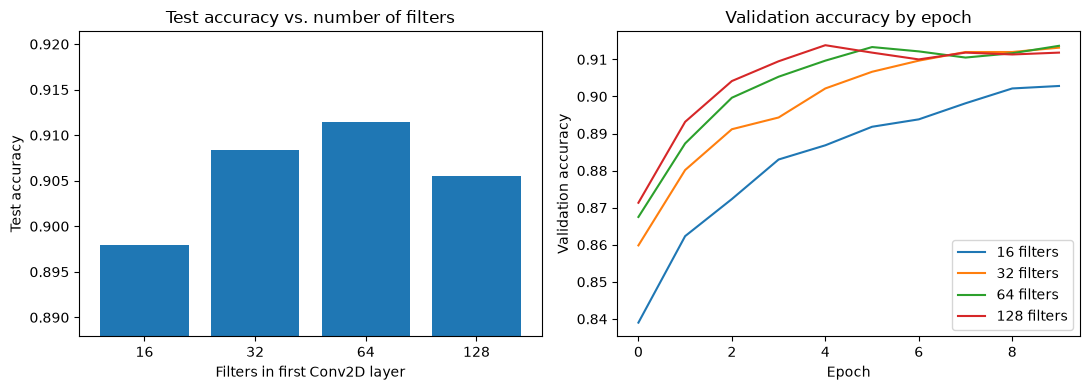

In [ ]:
# A. Test Hyperparameters
# Hyperparameter: number of filters in the first Conv2D layer (the second Conv2D uses 2x as many).
# Everything else (architecture, optimizer, epochs, batch size, seed) is held constant.
import numpy as np
import pandas as pd
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

EPOCHS = 10
BATCH_SIZE = 128

def build_cnn(n_filters, dropout=False):
    model = Sequential()  # new model each time so no weights carry over
    model.add(Input(shape=(28, 28, 1)))
    model.add(Conv2D(n_filters, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2)))
    model.add(Conv2D(n_filters * 2, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2)))
    model.add(Flatten())
    if dropout:
        model.add(Dropout(0.3))
    model.add(Dense(64, activation="relu"))
    if dropout:
        model.add(Dropout(0.3))
    model.add(Dense(10, activation="softmax"))
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

filter_values = [16, 32, 64, 128]
filter_results = []
filter_histories = {}

for n_filters in filter_values:
    tf.keras.utils.set_random_seed(42)
    model = build_cnn(n_filters)
    history = model.fit(X_train, y_train_cat, epochs=EPOCHS, batch_size=BATCH_SIZE,
                        validation_split=0.1, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
    filter_histories[n_filters] = history.history
    filter_results.append({
        "filters": n_filters,
        "params": model.count_params(),
        "train_acc": history.history["accuracy"][-1],
        "val_acc": history.history["val_accuracy"][-1],
        "test_acc": test_acc,
        "test_loss": test_loss,
    })
    print(f"filters={n_filters}: test acc={test_acc:.4f}, test loss={test_loss:.4f}")

filter_df = pd.DataFrame(filter_results)
display(filter_df.round(4))

best_filters = int(filter_df.loc[filter_df["test_acc"].idxmax(), "filters"])
print("Best number of filters:", best_filters)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar([str(f) for f in filter_values], filter_df["test_acc"])
axes[0].set_ylim(filter_df["test_acc"].min() - 0.01, filter_df["test_acc"].max() + 0.01)
axes[0].set_xlabel("Filters in first Conv2D layer")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Test accuracy vs. number of filters")
for f in filter_values:
    axes[1].plot(filter_histories[f]["val_accuracy"], label=f"{f} filters")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("Validation accuracy by epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

No dropout: test acc=0.9114, test loss=0.2702
With dropout: test acc=0.9091, test loss=0.2539


,model,filters,train_acc,val_acc,test_acc,test_loss,train_test_gap
0,No dropout,64,0.9484,0.9137,0.9114,0.2702,0.0370
1,With dropout,64,0.9139,0.9145,0.9091,0.2539,0.0048


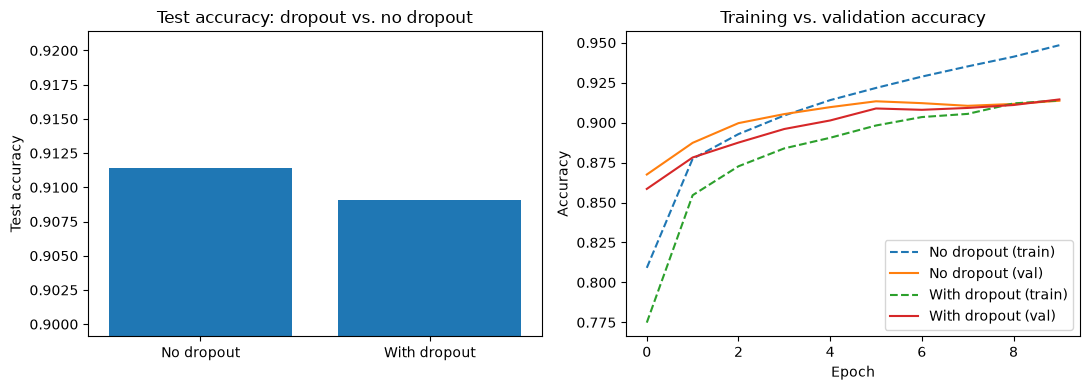

In [ ]:
# B. Test presence or absence of regularization
# Regularization: Dropout (0.3 before and after the hidden Dense layer), present vs. absent.
# Uses the best number of filters from experiment A; everything else is held constant.
reg_results = []
reg_histories = {}

for use_dropout in [False, True]:
    label = "With dropout" if use_dropout else "No dropout"
    tf.keras.utils.set_random_seed(42)
    model = build_cnn(best_filters, dropout=use_dropout)
    history = model.fit(X_train, y_train_cat, epochs=EPOCHS, batch_size=BATCH_SIZE,
                        validation_split=0.1, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
    reg_histories[label] = history.history
    reg_results.append({
        "model": label,
        "filters": best_filters,
        "train_acc": history.history["accuracy"][-1],
        "val_acc": history.history["val_accuracy"][-1],
        "test_acc": test_acc,
        "test_loss": test_loss,
    })
    print(f"{label}: test acc={test_acc:.4f}, test loss={test_loss:.4f}")

reg_df = pd.DataFrame(reg_results)
reg_df["train_test_gap"] = reg_df["train_acc"] - reg_df["test_acc"]
display(reg_df.round(4))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(reg_df["model"], reg_df["test_acc"])
axes[0].set_ylim(reg_df["test_acc"].min() - 0.01, reg_df["test_acc"].max() + 0.01)
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Test accuracy: dropout vs. no dropout")
for label, h in reg_histories.items():
    axes[1].plot(h["accuracy"], linestyle="--", label=f"{label} (train)")
    axes[1].plot(h["val_accuracy"], label=f"{label} (val)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training vs. validation accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

**Hyperparameter (filters in the first Conv2D; second uses 2x):** 16 → 89.8%, 32 → 90.8%, 64 → 91.1%, 128 → 90.6% test accuracy. Going from 16 to 64 filters helped by about 1.3 points, because more filters can learn more patterns. At 128 filters accuracy and test loss got worse (0.307 vs. 0.270): training accuracy kept rising (95.8%) while validation/test did not, so the larger model started to overfit and gave diminishing returns. The 32 and 64 filter models are close; 64 had the best accuracy and 32 had the lowest test loss.

**Regularization (dropout 0.3, using 64 filters):** Without dropout, test accuracy was 91.1% (loss 0.270); with dropout it was 90.9% (loss 0.254). Accuracy did not improve (the 0.2-point difference is within run-to-run noise), but dropout clearly reduced overfitting: the train-test accuracy gap shrank from 3.7 points to 0.5 points and test loss improved. With only 10 epochs the model had not yet overfit much, so dropout may help more with longer training.

**Best combination:** 64 filters (first layer) with no dropout gave the highest test accuracy (91.1%). 64 filters with dropout was nearly as accurate (90.9%) with better test loss and much less overfitting, so it is the more robust choice. These are single runs with one seed, so small differences should be treated with caution.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 11, 11, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 280,010 (1.07 MB)

 Trainable params: 280,010 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 - 19s - 45ms/step - accuracy: 0.7748 - loss: 0.6189 - val_accuracy: 0.8585 - val_loss: 0.3828
Epoch 2/10
422/422 - 13s - 31ms/step - accuracy: 0.8546 - loss: 0.4059 - val_accuracy: 0.8782 - val_loss: 0.3255
Epoch 3/10
422/422 - 10s - 25ms/step - accuracy: 0.8727 - loss: 0.3537 - val_accuracy: 0.8875 - val_loss: 0.2977
Epoch 4/10
422/422 - 23s - 55ms/step - accuracy: 0.8839 - loss: 0.3215 - val_accuracy: 0.8960 - val_loss: 0.2766
Epoch 5/10
422/422 - 22s - 52ms/step - accuracy: 0.8905 - loss: 0.3003 - val_accuracy: 0.9013 - val_loss: 0.2632
Epoch 6/10
422/422 - 13s - 30ms/step - accuracy: 0.8982 - loss: 0.2783 - val_accuracy: 0.9088 - val_loss: 0.2534
Epoch 7/10
422/422 - 11s - 27ms/step - accuracy: 0.9035 - loss: 0.2642 - val_accuracy: 0.9080 - val_loss: 0.2523
Epoch 8/10
422/422 - 12s - 29ms/step - accuracy: 0.9054 - loss: 0.2539 - val_accuracy: 0.9092 - val_loss: 0.2469
Epoch 9/10
422/422 - 12s - 29ms/step - accuracy: 0.9120 - loss: 0.2435 - val_accuracy: 0.9110 - 

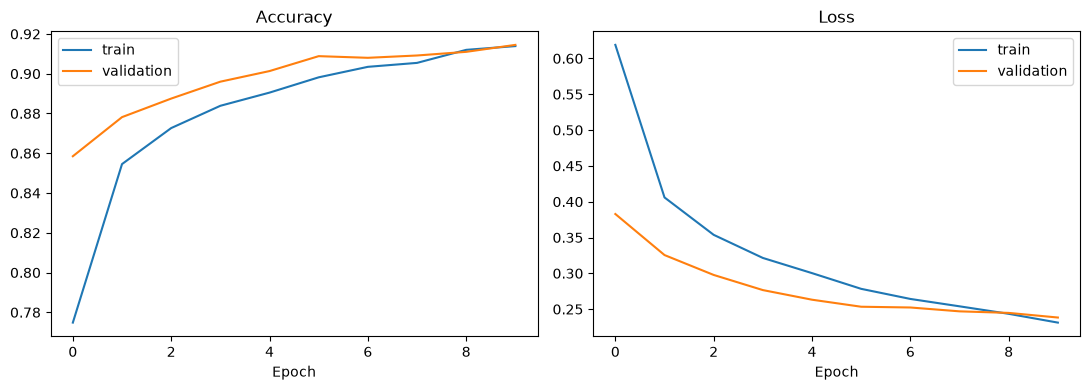

In [ ]:
# Final model: best settings from Part 4 (64 filters in the first Conv2D layer, with dropout)
from sklearn.metrics import classification_report

tf.keras.utils.set_random_seed(42)
final_model = build_cnn(64, dropout=True)
final_model.summary()

final_history = final_model.fit(X_train, y_train_cat, epochs=EPOCHS, batch_size=BATCH_SIZE,
                                validation_split=0.1, verbose=2)

final_loss, final_acc = final_model.evaluate(X_test, y_test_cat, verbose=0)
print(f"Final model - test loss: {final_loss:.4f}, test accuracy: {final_acc:.4f}")

# Per-class metrics
y_pred = np.argmax(final_model.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

# Learning curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(final_history.history["accuracy"], label="train")
axes[0].plot(final_history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(final_history.history["loss"], label="train")
axes[1].plot(final_history.history["val_loss"], label="validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**Comparison:** The final model (64 filters + dropout) reached 90.9% test accuracy (loss 0.254). That is above the linear baseline and above the first CNN. Most of the gain came from switching to a CNN. The tuning added only a small improvement.

**What contributed:** Convolutional layers learn local shapes and textures, which a linear model cannot. 64 filters gave more capacity than the first CNN (32 filters in the first layer).

**Next experiments:** Train for more epochs with early stopping, since validation accuracy was still rising. Tune the learning rate, dropout rate and batch size. Try L2 regularization, batch normalization or a deeper network. Add data augmentation such as small shifts and flips. Run several seeds to check that small differences are real.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 26/10/2025`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.